# 05 — Aplicação: risco e municípios acima/abaixo do esperado

Taxa esperada pelo contexto (previsões cross-fitted: cada município previsto por um modelo que não o viu), quadrantes em relação à meta de 60% e destaques (|z amostral| ≥ 2). Fonte: `reports/ranking_municipios.csv` (gerado por `python -m src.modeling.aplicacao`).

Os destaques indicam diferença em relação ao que o contexto medido prevê — candidatos a investigação (boas práticas ou apoio), não vereditos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.modeling import config
from src.modeling.aplicacao import resumo_por_uf

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 20)
IMAGES = Path("images")

ranking = pd.read_csv("reports/ranking_municipios.csv", dtype={"id_municipio": str})
print(f"{len(ranking):,} municípios\n")

contagem = pd.crosstab(ranking["quadrante"], ranking["destaque"], margins=True, margins_name="Total")
print(contagem.to_string())

5,450 municípios

destaque                                        Abaixo do esperado  Dentro da variação esperada  Supera o esperado  Total
quadrante                                                                                                                
Abaixo da meta, apesar do contexto favorável                   106                          572                  0    678
Abaixo da meta, como esperado pelo contexto                     41                         1636                  1   1678
Acima da meta, apesar do contexto desfavorável                   0                          352                 67    419
Acima da meta, como esperado                                     3                         2617                 55   2675
Total                                                          150                         5177                123   5450


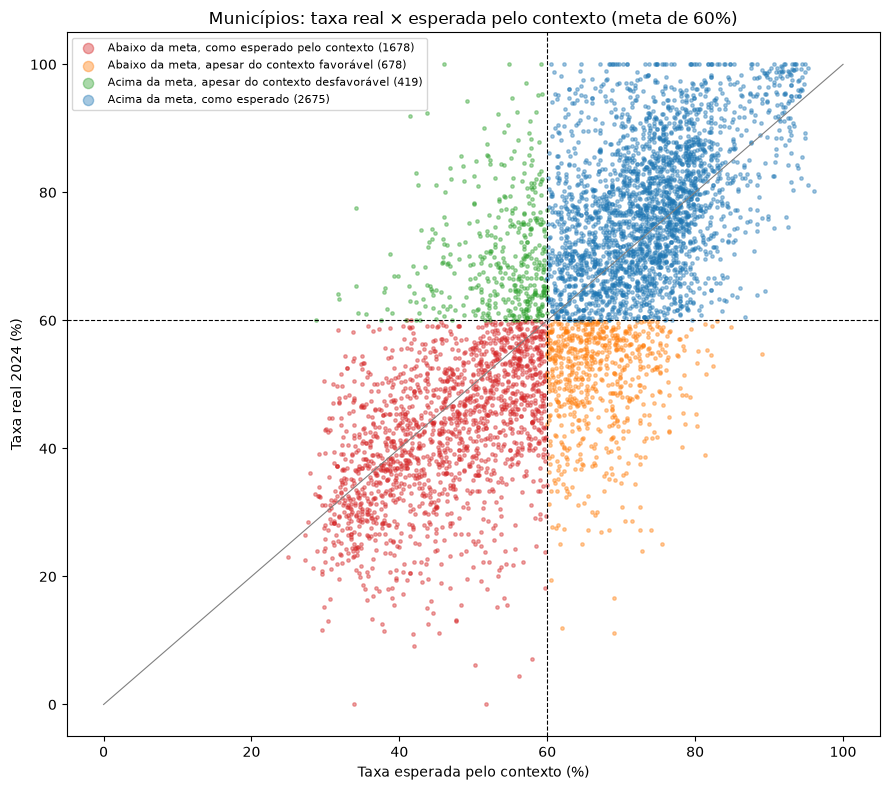

In [2]:
cores = {
    "Abaixo da meta, como esperado pelo contexto": "#d62728",
    "Abaixo da meta, apesar do contexto favorável": "#ff7f0e",
    "Acima da meta, apesar do contexto desfavorável": "#2ca02c",
    "Acima da meta, como esperado": "#1f77b4",
}

fig, ax = plt.subplots(figsize=(9, 8))
for quadrante, cor in cores.items():
    sub = ranking[ranking["quadrante"] == quadrante]
    ax.scatter(sub["taxa_prevista"], sub["taxa_real"], s=6, alpha=0.4, color=cor, label=f"{quadrante} ({len(sub)})")
ax.axhline(config.LIMIAR_RISCO, color="black", lw=0.8, ls="--")
ax.axvline(config.LIMIAR_RISCO, color="black", lw=0.8, ls="--")
ax.plot([0, 100], [0, 100], color="gray", lw=0.8)
ax.set_xlabel("Taxa esperada pelo contexto (%)")
ax.set_ylabel("Taxa real 2024 (%)")
ax.set_title("Municípios: taxa real × esperada pelo contexto (meta de 60%)")
ax.legend(loc="upper left", fontsize=8, markerscale=3)
plt.tight_layout()
plt.savefig(IMAGES / "09_quadrantes.png", dpi=120, bbox_inches="tight")
plt.show()

    municipios    alunos  taxa_real_ponderada  taxa_prevista_ponderada  pct_abaixo_meta_real  pct_abaixo_meta_prevista  n_supera_esperado  n_abaixo_esperado
uf                                                                                                                                                          
BA       407.0  115273.0                 35.9                     36.2                  97.3                     100.0                4.0                1.0
SE        75.0   17102.0                 38.1                     37.8                  96.0                     100.0                2.0                2.0
RN       167.0   24763.0                 38.2                     38.8                  88.6                      99.4                2.0                3.0
RS       456.0   74100.0                 44.3                     46.1                  68.6                      78.9                5.0               14.0
AM        62.0   45079.0                 46.5             

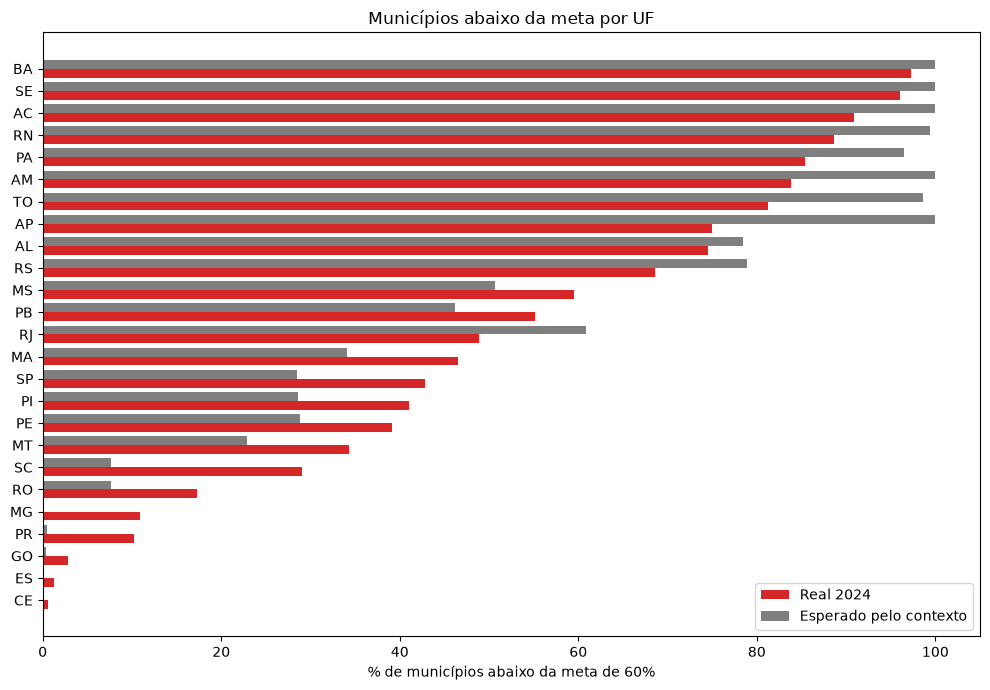

In [3]:
por_uf = resumo_por_uf(ranking)
print(por_uf.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 7))
ordem = por_uf.sort_values("pct_abaixo_meta_real")
y = np.arange(len(ordem))
ax.barh(y - 0.2, ordem["pct_abaixo_meta_real"], height=0.4, label="Real 2024", color="#d62728")
ax.barh(y + 0.2, ordem["pct_abaixo_meta_prevista"], height=0.4, label="Esperado pelo contexto", color="#7f7f7f")
ax.set_yticks(y)
ax.set_yticklabels(ordem.index)
ax.set_xlabel("% de municípios abaixo da meta de 60%")
ax.set_title("Municípios abaixo da meta por UF")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "10_risco_por_uf.png", dpi=120, bbox_inches="tight")
plt.show()

In [4]:
colunas = ["nome_municipio", "uf", "n_alunos", "taxa_real", "taxa_prevista", "residuo_pp", "z"]

supera = ranking[(ranking["quadrante"] == "Acima da meta, apesar do contexto desfavorável")
                 & (ranking["destaque"] == "Supera o esperado")]
print(f"Superam a meta apesar do contexto desfavorável, com destaque: {len(supera)}")
print(supera.sort_values("z", ascending=False)[colunas].head(15).to_string(index=False))

abaixo = ranking[(ranking["quadrante"] == "Abaixo da meta, apesar do contexto favorável")
                 & (ranking["destaque"] == "Abaixo do esperado")]
print(f"\nAbaixo da meta apesar do contexto favorável, com destaque: {len(abaixo)}")
print(abaixo.sort_values("z")[colunas].head(15).to_string(index=False))

Superam a meta apesar do contexto desfavorável, com destaque: 67
       nome_municipio uf  n_alunos  taxa_real  taxa_prevista  residuo_pp    z
               Japurá AM        96       91.9           41.4        50.5 3.93
      Tartarugalzinho AP       294       94.2           49.1        45.2 3.71
          Riacho Frio PI        66       92.4           43.8        48.6 3.66
  São Miguel de Taipu PB        28      100.0           46.0        54.0 3.57
                Anori AM       209       77.5           34.1        43.4 3.54
               Inhapi AL       221       83.0           42.3        40.7 3.31
   União dos Palmares AL       643       94.8           55.2        39.5 3.30
             Coruripe AL       817       92.2           53.4        38.7 3.24
 Santana de Mangueira PB        44      100.0           54.8        45.2 3.23
         Porto de Moz PA       484       81.2           42.5        38.7 3.21
Porto Real do Colégio AL       142       83.8           46.8        37.0 2.95

## Conclusões

**Quadrantes (meta de 60%):** 1.678 municípios abaixo da meta como o contexto prevê; 678 abaixo apesar do contexto favorável; 419 acima apesar do contexto desfavorável; 2.675 acima como esperado.

**Incerteza:** a variação que o contexto medido não explica tem desvio-padrão de 11,8 p.p. — o limite do que dados municipais conseguem prever.

**Destaques (|z| ≥ 2, com incerteza amostral + não explicada):** 273 municípios (5,0%) — 123 acima e 150 abaixo do esperado. A proporção é próxima da esperada por acaso numa distribuição normal (~4,6%): os destaques são **os municípios mais distantes do esperado**, não anomalias estatísticas. Servem para priorizar investigação:
- **67 acima da meta apesar do contexto desfavorável** — candidatos a estudo de boas práticas;
- **106 abaixo da meta apesar do contexto favorável** — investigar gestão local ou a qualidade da medida;
- **41 abaixo da meta e bem abaixo do esperado mesmo com contexto desfavorável** — prioridade máxima de apoio.

**Cuidados:** resíduos muito grandes (40–50 p.p.) podem refletir política local, mas também problemas de aplicação ou registro da avaliação; redes muito pequenas seguem sensíveis a poucos alunos. A taxa prevista é um escore de risco para ordenar municípios — as previsões são mais concentradas que a realidade (o modelo encolhe em direção à média do estado), então não devem ser usadas para estimar quantos municípios ficarão abaixo da meta.